ORIGINAL TRAFFIC INCIDENTS DATA LOADED
         Date         Time                  Type  \
0  01/24/2026  09:56:22 AM    Stalled/Hazard Veh   
1  01/24/2026  09:54:49 AM      Hazardous Driver   
2  01/24/2026  09:47:29 AM                   MVC   
3  01/24/2026  09:43:15 AM                   MVC   
4  01/24/2026  09:40:24 AM                   MVC   
5  01/24/2026  09:37:33 AM     Traffic Complaint   
6  01/24/2026  09:08:28 AM      Hazardous Driver   
7  01/24/2026  09:06:49 AM     Traffic Complaint   
8  01/24/2026  08:39:02 AM  Traffic Control Devi   
9  01/24/2026  08:30:04 AM  Traffic Control Devi   

                          Address             Location       Area  
0           Pali Hwy / Nuuanu Ave                  NaN     Nuuanu  
1           920789 Farrington Hwy         HONOKAI HALE    Kapolei  
2         Maunakea St / N King St                  NaN   Downtown  
3               3018 Hollinger St                  NaN   Kapahulu  
4           950550 Lanikuhana Ave     WALMART MI

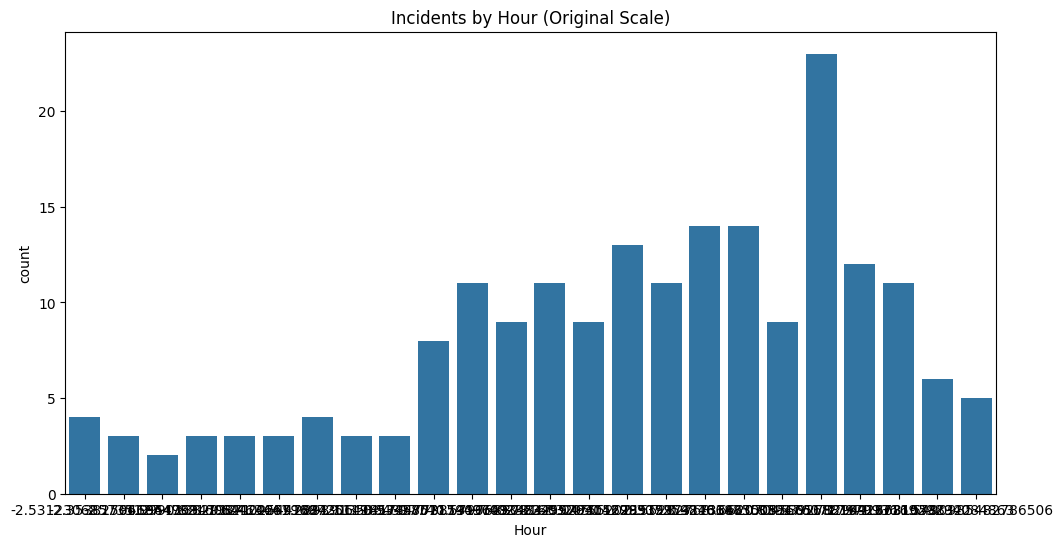

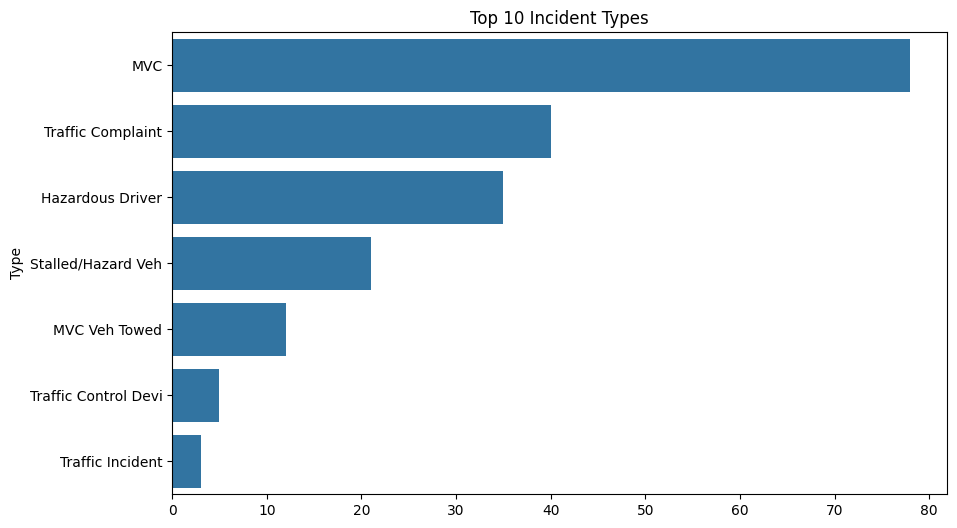


FINAL ENGINEERED DATASET READY FOR ML
                   Type       Area      Hour DayOfWeek  IsWeekend  IsRushHour  \
0    Stalled/Hazard Veh     Nuuanu -0.934580  Saturday       True           1   
1      Hazardous Driver    Kapolei -0.934580  Saturday       True           1   
2                   MVC   Downtown -0.934580  Saturday       True           1   
3                   MVC   Kapahulu -0.934580  Saturday       True           1   
4                   MVC   Mililani -0.934580  Saturday       True           1   
5     Traffic Complaint     Kalihi -0.934580  Saturday       True           1   
6      Hazardous Driver    Waipahu -0.934580  Saturday       True           1   
7     Traffic Complaint       Aiea -0.934580  Saturday       True           1   
8  Traffic Control Devi    Waianae -1.111986  Saturday       True           1   
9  Traffic Control Devi  Ewa Beach -1.111986  Saturday       True           1   

   IsHighSeverity  IsHotspotArea  Type_encoded  Area_encoded  \
0    

In [3]:
"""
Traffic Incidents Feature Engineering & Preprocessing Pipeline
Honolulu Traffic Incidents Dataset (Jan 23-24, 2026)
@author: https://github.com/DocOhms/jupyter-notebook_data-analysis
Dataset: Traffic_Incidents.csv (Honolulu Police/Traffic real-time reports)
Purpose: Clean, engineer, and prepare incident data for downstream ML tasks
         (e.g., incident type prediction, hotspot forecasting, severity modeling)
"""

# Import libraries
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, LabelEncoder
import matplotlib.pyplot as plt
import seaborn as sns

class TrafficIncidentsEngineering:
    def __init__(self):
        self.df = None
    
    def create_DFrame_from_csv(self, file_path="Traffic_Incidents.csv"):
        try:
            df = pd.read_csv(file_path)
            print("ORIGINAL TRAFFIC INCIDENTS DATA LOADED")
            print(df.head(10))
            print(f"\nShape: {df.shape}")
            print(f"\nInfo:\n{df.info()}")
            self.df = df
        except FileNotFoundError:
            print(f"Error: The file '{file_path}' was not found. Upload it to your notebook.")
        except Exception as e:
            print("An error occurred:", e)
    
    def Handle_Missing_Values(self):
        if self.df is None:
            print("Load data first!")
            return
        
        df = self.df
        print("\nMissing values before handling:")
        print(df.isnull().sum())
        
        # Minimal missing in this dataset, but handle safely
        df['Area'] = df['Area'].fillna('Unknown')
        df['Address'] = df['Address'].fillna('Unknown')
        df['Location'] = df['Location'].fillna('Unknown')
        
        # Combine Date + Time into proper datetime
        df['FullDateTime'] = pd.to_datetime(
            df['Date'] + ' ' + df['Time'],
            format='%m/%d/%Y %I:%M:%S %p',
            errors='coerce'
        )
        df = df.dropna(subset=['FullDateTime']).reset_index(drop=True)
        
        print("\nMISSING VALUES HANDLED & DATETIME COMBINED")
        print(df.head(10))
        self.df = df
    
    def Feature_Creation(self):
        if self.df is None:
            print("Load and clean data first!")
            return
        
        df = self.df
        
        # Time-based features
        df['Hour'] = df['FullDateTime'].dt.hour
        df['DayOfWeek'] = df['FullDateTime'].dt.day_name()
        df['IsWeekend'] = df['FullDateTime'].dt.weekday >= 5
        df['IsRushHour'] = df['Hour'].apply(lambda h: 1 if h in [6,7,8,9,16,17,18,19] else 0)
        
        # Incident severity proxy (simple heuristic)
        high_severity_types = ['MVC', 'MVC Veh Towed']
        df['IsHighSeverity'] = df['Type'].isin(high_severity_types).astype(int)
        
        # Area hotspot flag (top 10 areas get flag)
        top_areas = df['Area'].value_counts().head(10).index
        df['IsHotspotArea'] = df['Area'].isin(top_areas).astype(int)
        
        print("\nNEW FEATURES CREATED")
        print(df[['Type', 'Area', 'Hour', 'DayOfWeek', 'IsRushHour', 'IsHighSeverity', 'IsHotspotArea']].head(15))
        self.df = df
    
    def Feature_Transformation(self):
        if self.df is None:
            print("Complete previous steps first!")
            return
        
        df = self.df
        
        # Scaling numeric features
        scaler = StandardScaler()
        numeric_cols = ['Hour']
        df[numeric_cols] = scaler.fit_transform(df[numeric_cols])
        
        # Label encoding categorical features
        le_type = LabelEncoder()
        le_area = LabelEncoder()
        le_day = LabelEncoder()
        
        df['Type_encoded'] = le_type.fit_transform(df['Type'])
        df['Area_encoded'] = le_area.fit_transform(df['Area'])
        df['DayOfWeek_encoded'] = le_day.fit_transform(df['DayOfWeek'])
        
        print("\nFEATURES SCALED & ENCODED")
        print(df[['Type_encoded', 'Area_encoded', 'DayOfWeek_encoded', 'Hour', 'IsRushHour']].head(10))
        self.df = df
    
    def Feature_Selection_and_Exploration(self):
        if self.df is None:
            print("Complete previous steps first!")
            return
        
        df = self.df
        
        # Drop raw text columns not needed for modeling
        cols_to_drop = ['Date', 'Time', 'Address', 'Location', 'FullDateTime']
        df_model = df.drop(columns=cols_to_drop)
        
        # Correlation check example
        corr_matrix = df_model.select_dtypes(include=[np.number]).corr()
        print("\nCORRELATION MATRIX (numeric features)")
        print(corr_matrix)
        
        # Simple visualization
        plt.figure(figsize=(12, 6))
        sns.countplot(data=df, x='Hour', order=sorted(df['Hour'].unique()))
        plt.title('Incidents by Hour (Original Scale)')
        plt.show()
        
        plt.figure(figsize=(10, 6))
        top_types = df['Type'].value_counts().head(10)
        sns.barplot(x=top_types.values, y=top_types.index)
        plt.title('Top 10 Incident Types')
        plt.show()
        
        print("\nFINAL ENGINEERED DATASET READY FOR ML")
        print(df_model.head(10))
        print(f"\nFinal shape: {df_model.shape}")
        self.df_final = df_model

# ---------------------------- Class Driver ----------------------------
incidents = TrafficIncidentsEngineering()
incidents.create_DFrame_from_csv("Traffic_Incidents.csv")
incidents.Handle_Missing_Values()
incidents.Feature_Creation()
incidents.Feature_Transformation()
incidents.Feature_Selection_and_Exploration()